#### We have the following setting: We have two observables, x,y, and we observe them in two environments, an envirnoment where they behave normally and an environment that shows faulty behavior. From the normal behaving environment we assume to have many samples, while in the faulty environment we only have a SINGLE observation. For example we observe in a single instance that both X and Y show big deviations from the mean of the normal behaving values.

#### The task: can we identify, without knowing the ground truth causal structure X->Y, if X caused Y or Y caused X?

In [1]:
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

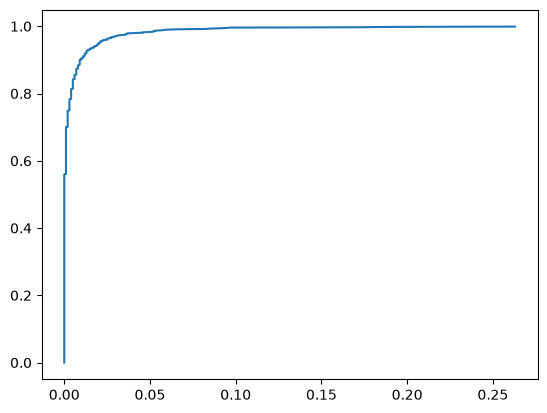

In [ ]:

pvals=[]
for i in range(1000):
    # Data creation with model X->Y in the normal environment
    x_normal=np.random.normal(0,1,size=(1000,1))
    y_normal=x_normal+np.random.normal(0,1,size=(1000,1))

    # Data creation with model X->Y in the faulty environment
    x_faulty=np.array(5,) # The root cause fault, a SINGLE point distincly away from the normal behavior
    y_faulty=x_faulty+np.random.normal(0,1) # Y is now also affected

    # Test hypothesis (informally): Does the model Y->X explain the data causally? 
    # For that we build a linear model (based on normal data) in that direction and inspect the residual of the fault point
    # Based on the residuals of the normal environment we construct a p-value
    model=LinearRegression()
    model.fit(y_normal,x_normal)
    residuals_normal=(x_normal-model.predict(y_normal))**2
    residuals_faulty=(x_faulty-model.predict(y_faulty.reshape(1, -1)))**2
    pvals.append(min(1-np.mean(residuals_faulty>residuals_normal),1-np.mean(residuals_faulty<residuals_normal)))
    pvals.append(1 - np.mean(residuals_faulty>residuals_normal))
    
plt.plot(np.sort(pvals), np.linspace(0, 1, len(pvals), endpoint=False))

## We see power for rejecting this hypotheis

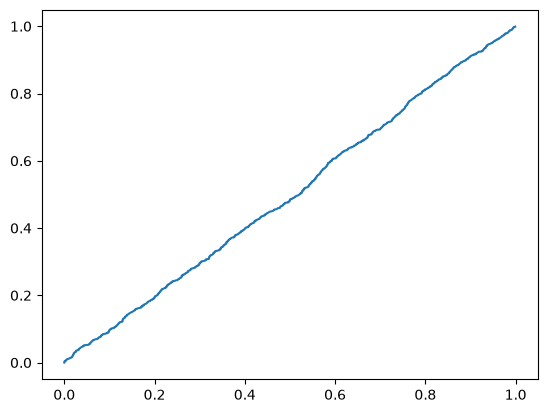

In [3]:

pvals=[]
for i in range(1000):
        # Data creation with model X->Y in the normal environment
    x_normal=np.random.normal(0,1,size=(1000,1))
    y_normal=x_normal+np.random.normal(0,1,size=(1000,1))

    # Data creation with model X->Y in the faulty environment
    x_faulty=np.array(5,) # The root cause fault, a point distincly away from the normal behavior
    y_faulty=x_faulty+np.random.normal(0,1)

    # Test hypothesis (informally): Does the model X->Y explain the data causally? This is by design the true null hypothesis,
    # so we will see a uniform distribution for p-values
    model=LinearRegression() 
    model.fit(x_normal,y_normal) # We fit the model in the correct direction X->Y
    residuals_normal=(y_normal-model.predict(x_normal))**2
    residuals_faulty=(y_faulty-model.predict(x_faulty.reshape(1, -1)))**2

    # The main test: we test if residuals_faulty is larger than the residuals_normal
    pvals.append(1-np.mean(residuals_faulty>residuals_normal))
plt.plot(np.sort(pvals), np.linspace(0, 1, len(pvals), endpoint=False))